# EV Home Energy Management Digital Twin
Run all cells in Google Colab. The final cell creates a public Gradio demo link for presentation.

             EV HOME ENERGY MANAGEMENT SYSTEM


,Time,EV Power (kW),Tariff (₹/kWh),EV SOC (%),Household Load (kW),Solar (kW),Grid Demand (kW),Decision
0,00:00,0.0,3.8,45.00,3.16,0.00,3.16,IDLE
1,01:00,2.0,3.8,49.75,3.09,0.00,5.09,CHARGE
2,02:00,2.0,3.8,54.50,2.82,0.00,4.82,CHARGE
3,03:00,2.0,3.8,59.25,3.02,0.00,5.02,CHARGE
4,04:00,2.0,3.8,64.00,3.20,0.00,5.20,CHARGE
5,05:00,2.0,3.8,68.75,3.36,0.00,5.36,CHARGE
6,06:00,0.0,5.8,68.75,3.97,0.00,3.97,IDLE
7,07:00,0.0,5.8,68.75,4.21,0.00,4.21,IDLE
8,08:00,0.0,5.8,68.75,3.94,0.77,3.16,IDLE
9,09:00,0.0,5.8,68.75,3.42,1.47,1.95,IDLE


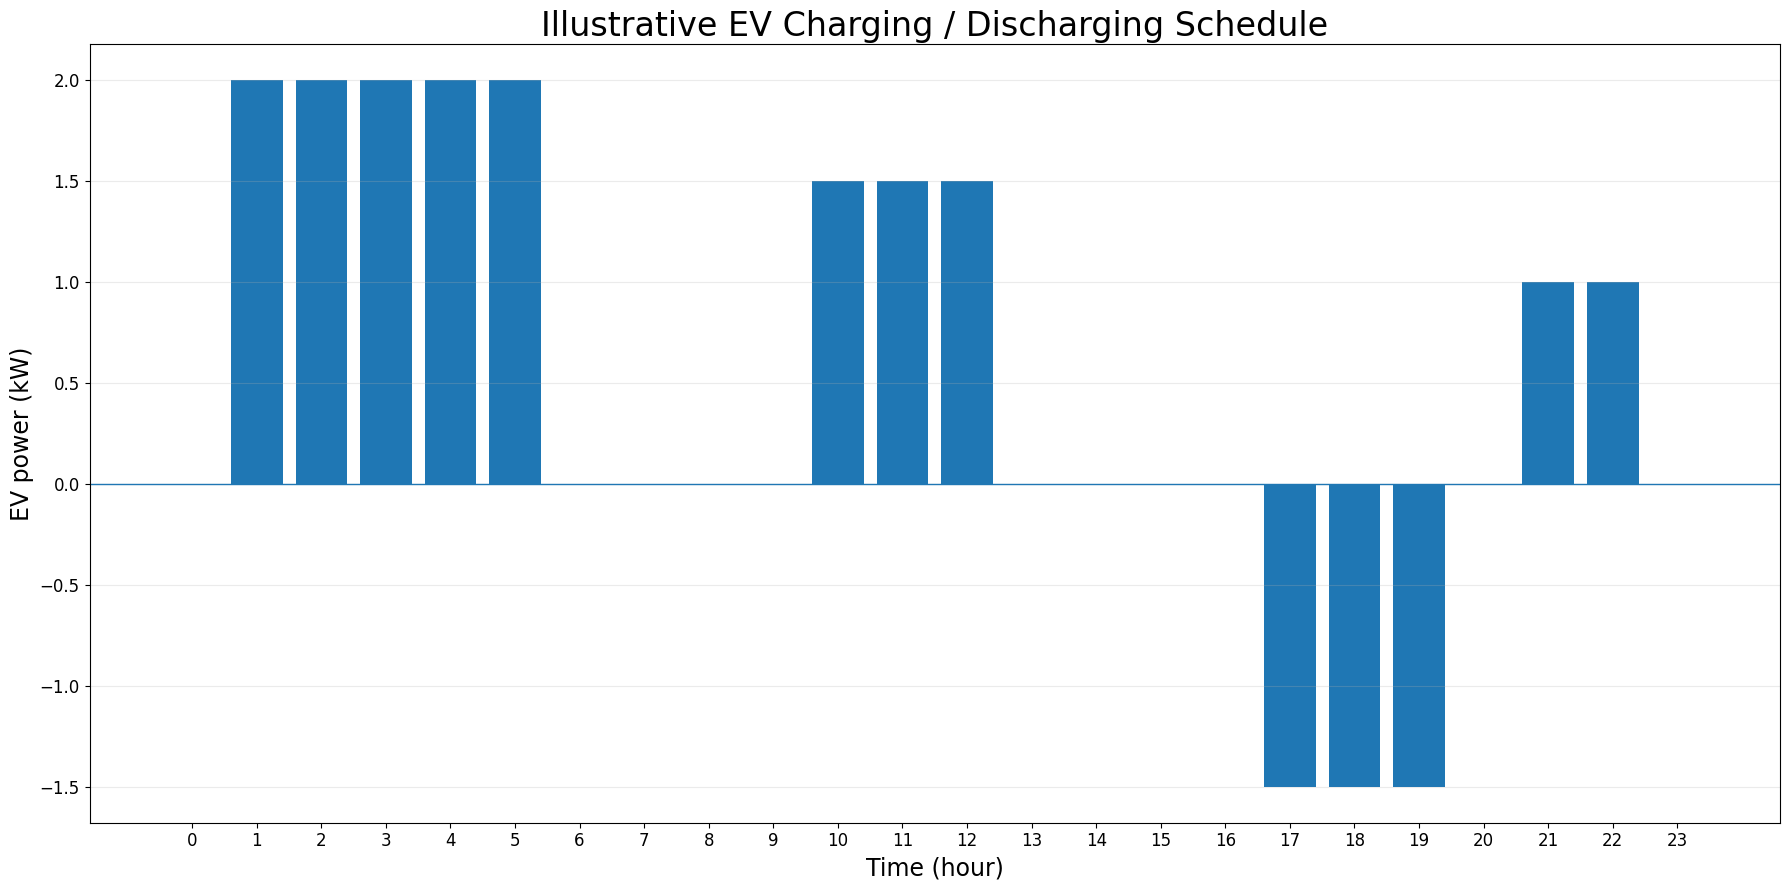

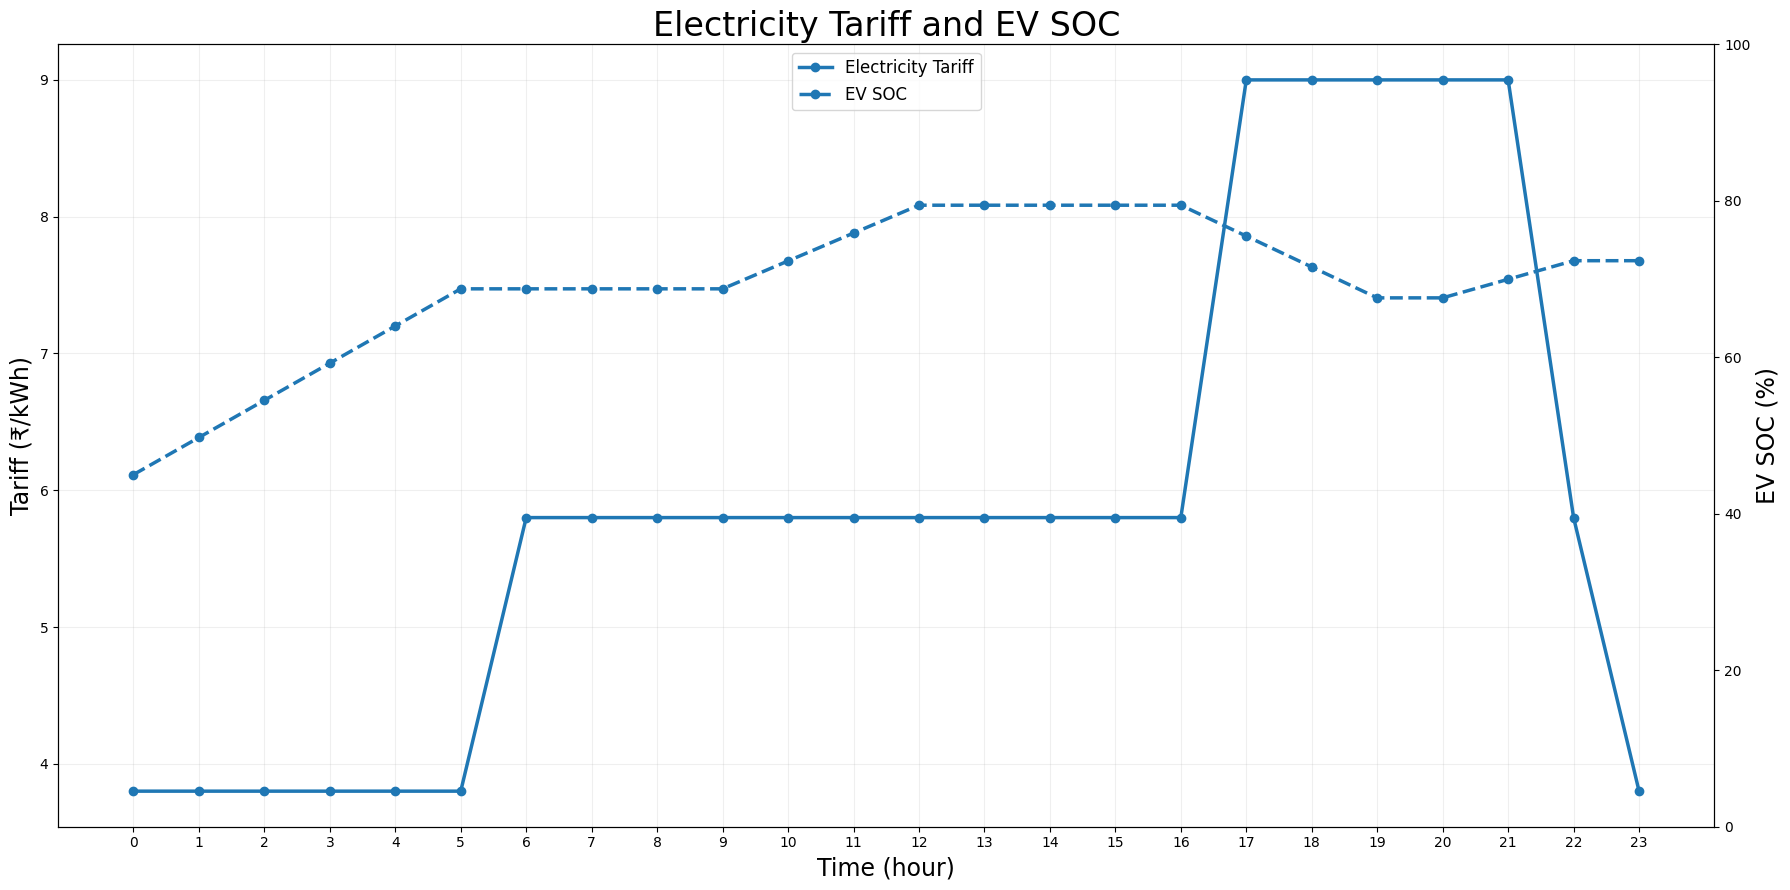

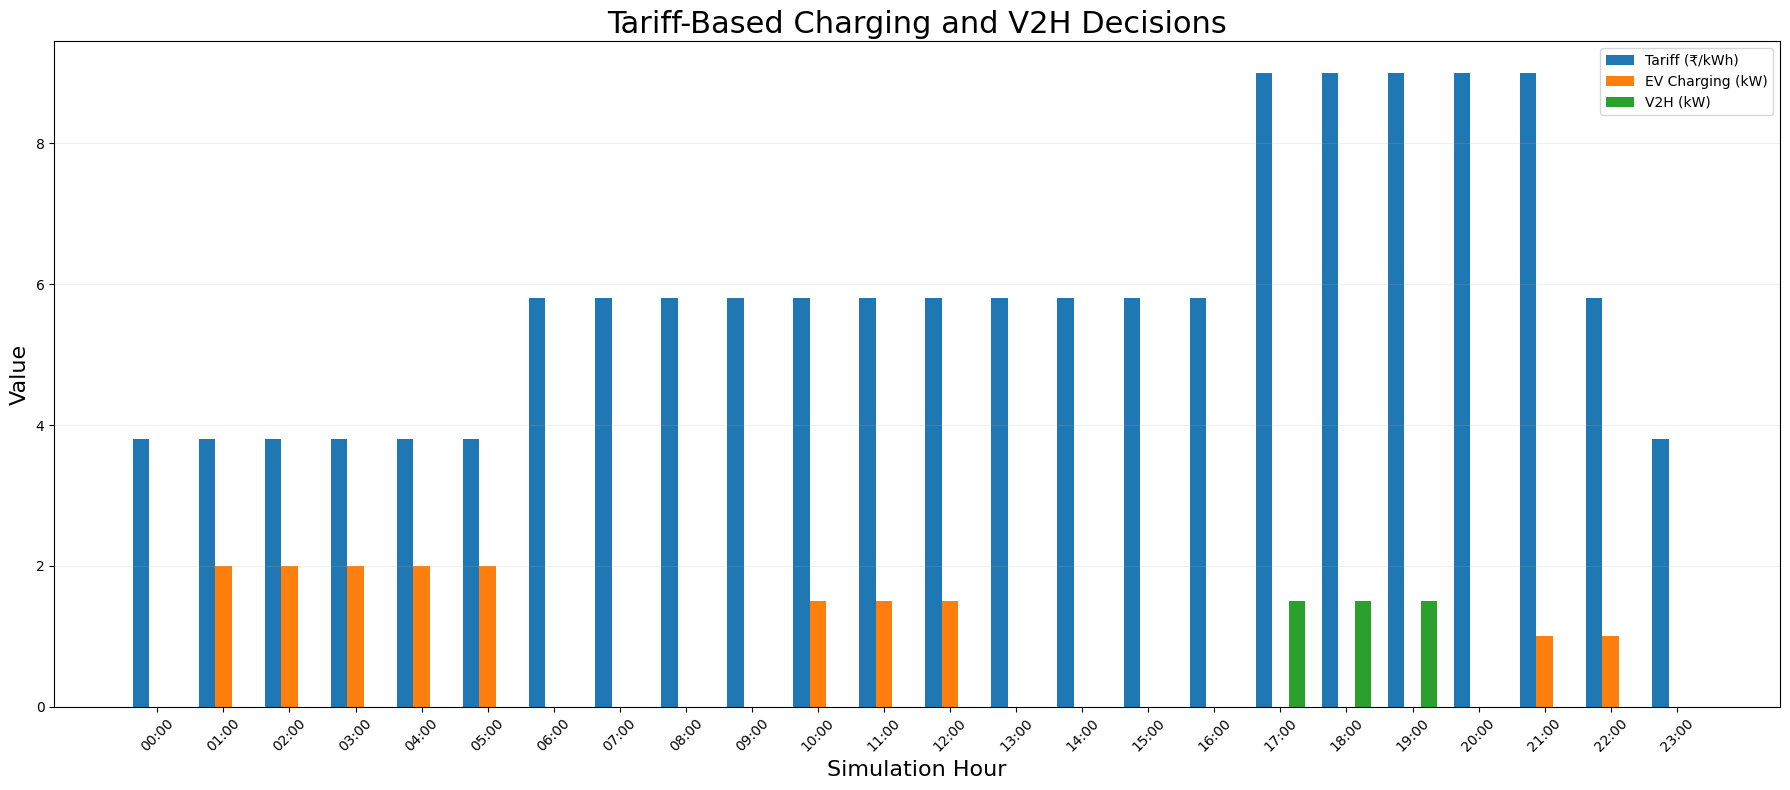

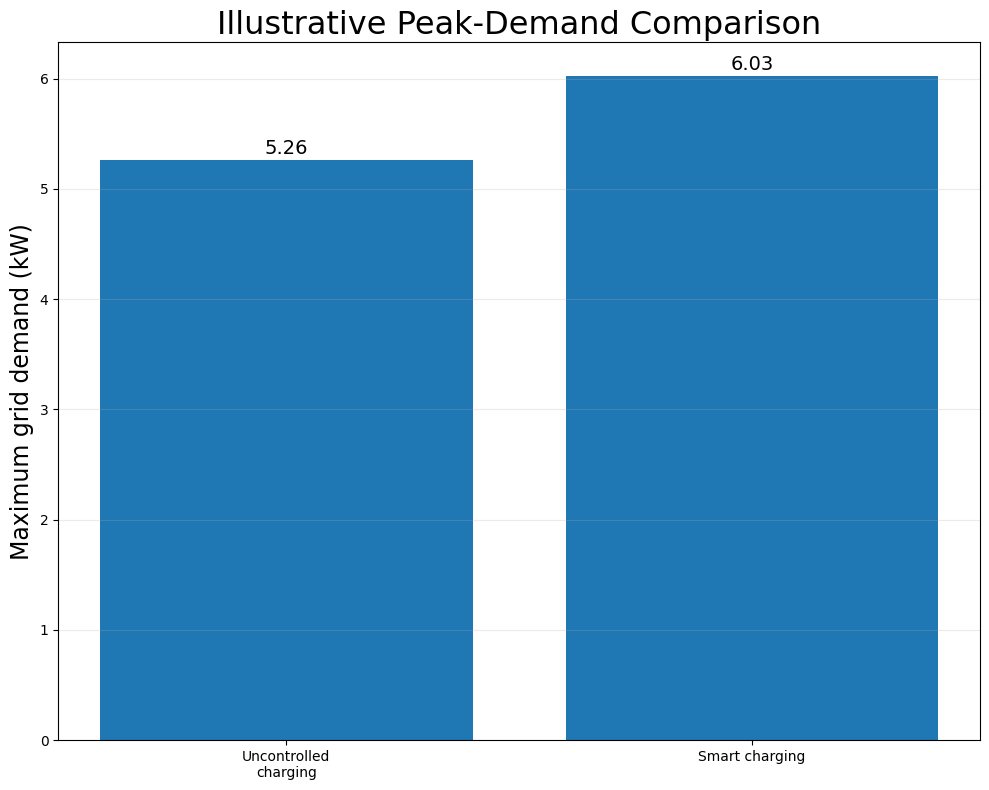

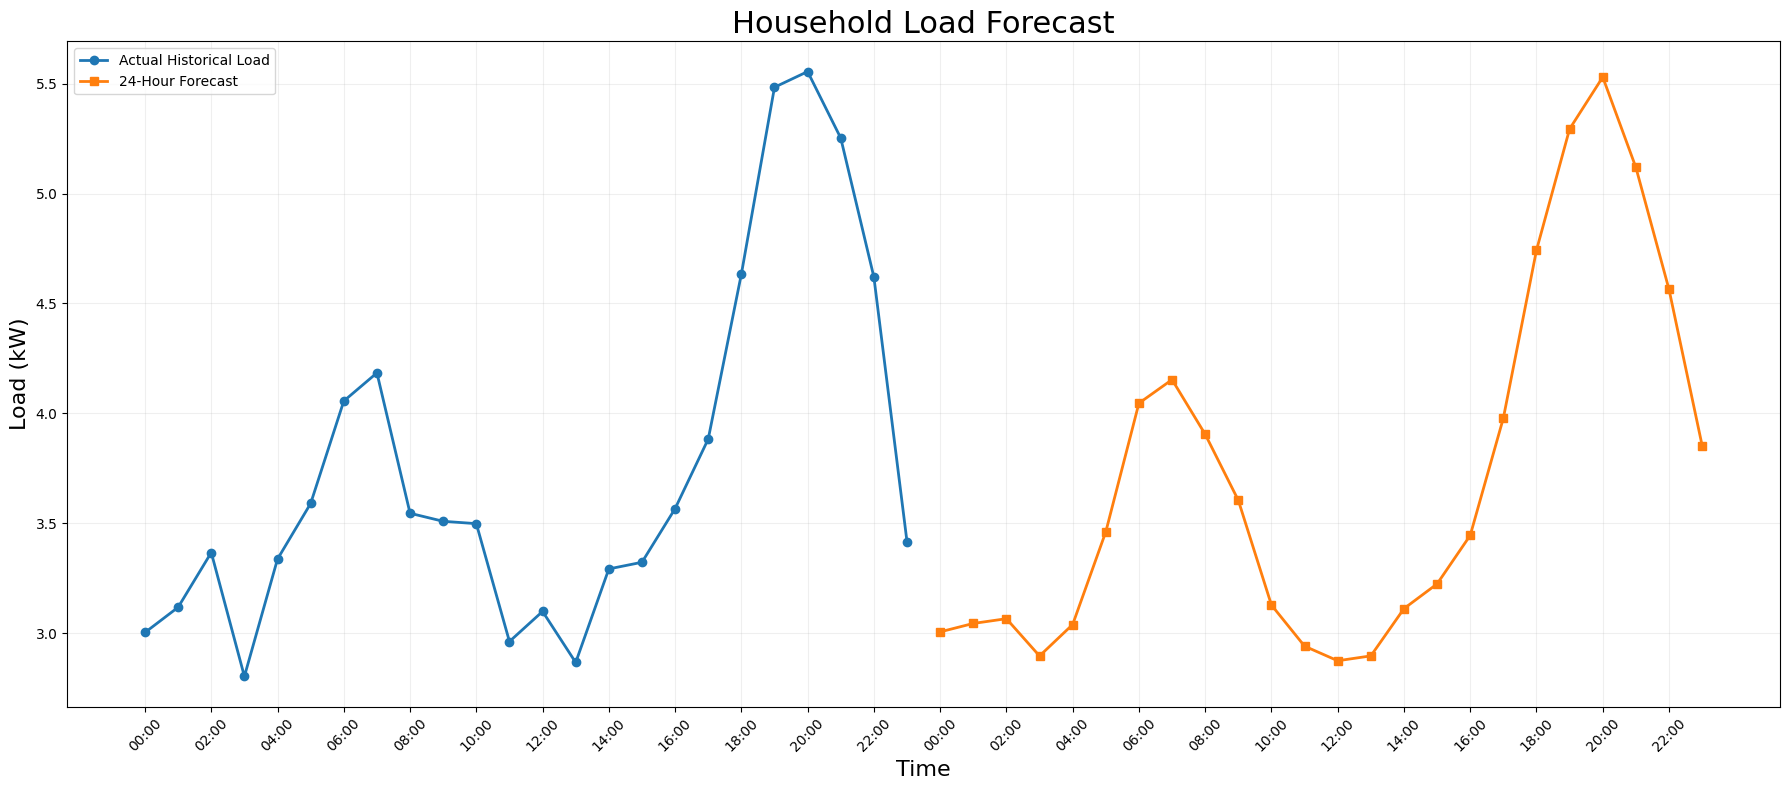


                    FINAL RESULTS
Forecast MAE       : 0.15 kW
Forecast RMSE      : 0.19 kW
Forecast MAPE      : 4.07%
Initial EV SOC     : 45.0%
Final EV SOC       : 72.3%
Baseline Cost      : ₹494.52
Smart Cost         : ₹494.92
Cost Saving        : ₹-0.40
Baseline Peak      : 5.26 kW
Smart Peak         : 6.03 kW
Peak Reduction     : -0.77 kW

Charging hours:
['01:00', '02:00', '03:00', '04:00', '05:00', '10:00', '11:00', '12:00', '21:00', '22:00']

V2H / Discharging hours:
['17:00', '18:00', '19:00']


In [1]:
# ============================================================
# CORRECT 24-HOUR EV CHARGING / DISCHARGING SCHEDULE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Actual clock hours
hours = np.arange(24)

# ------------------------------------------------------------
# EV POWER SCHEDULE
#
# Positive value  = EV CHARGING
# Negative value  = EV DISCHARGING / V2H
# Zero             = IDLE
# ------------------------------------------------------------

ev_power = np.zeros(24)

# Charging: 01:00 - 05:00
ev_power[1:6] = 2.0

# Charging: 10:00 - 12:00
ev_power[10:13] = 1.5

# V2H / Discharging: 17:00 - 19:00
ev_power[17:20] = -1.5

# Charging: 21:00 - 22:00
ev_power[21:23] = 1.0


# ============================================================
# EV SOC CALCULATION
# ============================================================

BATTERY_CAPACITY = 40.0
INITIAL_SOC = 45.0

CHARGE_EFFICIENCY = 0.95
DISCHARGE_EFFICIENCY = 0.95

soc = np.zeros(24)

energy = (
    BATTERY_CAPACITY
    * INITIAL_SOC
    / 100
)

for h in hours:

    # Charging
    if ev_power[h] > 0:

        energy += (
            ev_power[h]
            * CHARGE_EFFICIENCY
        )

    # Discharging / V2H
    elif ev_power[h] < 0:

        energy -= (
            abs(ev_power[h])
            / DISCHARGE_EFFICIENCY
        )

    # Battery limits
    energy = np.clip(
        energy,
        BATTERY_CAPACITY * 0.20,
        BATTERY_CAPACITY
    )

    soc[h] = (
        energy
        / BATTERY_CAPACITY
        * 100
    )


# ============================================================
# ELECTRICITY TARIFF
# ============================================================

tariff = np.zeros(24)

for h in hours:

    if h >= 23 or h < 6:

        tariff[h] = 3.8

    elif 17 <= h < 22:

        tariff[h] = 9.0

    else:

        tariff[h] = 5.8


# ============================================================
# DECISION LABEL
# ============================================================

decision = []

for h in hours:

    if ev_power[h] > 0:

        decision.append("CHARGE")

    elif ev_power[h] < 0:

        decision.append("V2H")

    else:

        decision.append("IDLE")


# ============================================================
# HOUSEHOLD LOAD
# ============================================================

np.random.seed(10)

household_load = (
    3.0
    + 1.2 * np.exp(
        -((hours - 7) / 2.0) ** 2
    )
    + 2.5 * np.exp(
        -((hours - 20) / 3.0) ** 2
    )
    + np.random.normal(
        0,
        0.12,
        24
    )
)

household_load = np.maximum(
    household_load,
    1.5
)


# ============================================================
# SOLAR GENERATION
# ============================================================

solar = np.zeros(24)

for h in hours:

    if 7 <= h <= 17:

        solar[h] = (
            2.5
            * np.sin(
                np.pi
                * (h - 7)
                / 10
            )
        )

        solar[h] = max(
            solar[h],
            0
        )


# ============================================================
# GRID DEMAND - SMART MANAGEMENT
# ============================================================

grid_smart = np.maximum(
    household_load
    - solar
    + np.maximum(
        ev_power,
        0
    )
    + np.minimum(
        ev_power,
        0
    ),
    0
)


# ============================================================
# BASELINE / UNCONTROLLED CHARGING
# ============================================================

baseline_ev_power = np.zeros(24)

# Immediately charge during the initial period
baseline_ev_power[0:5] = 2.0

grid_baseline = np.maximum(
    household_load
    - solar
    + baseline_ev_power,
    0
)


# ============================================================
# COST CALCULATION
# ============================================================

smart_cost = np.sum(
    grid_smart
    * tariff
)

baseline_cost = np.sum(
    grid_baseline
    * tariff
)

cost_saving = (
    baseline_cost
    - smart_cost
)


# ============================================================
# PEAK DEMAND
# ============================================================

smart_peak = np.max(
    grid_smart
)

baseline_peak = np.max(
    grid_baseline
)

peak_reduction = (
    baseline_peak
    - smart_peak
)


# ============================================================
# PRINT SCHEDULE
# ============================================================

schedule = pd.DataFrame({

    "Time":
        [
            f"{h:02d}:00"
            for h in hours
        ],

    "EV Power (kW)":
        ev_power,

    "Tariff (₹/kWh)":
        tariff,

    "EV SOC (%)":
        soc,

    "Household Load (kW)":
        household_load,

    "Solar (kW)":
        solar,

    "Grid Demand (kW)":
        grid_smart,

    "Decision":
        decision
})

schedule = schedule.round(2)

print("=" * 80)
print("             EV HOME ENERGY MANAGEMENT SYSTEM")
print("=" * 80)

display(schedule)


# ============================================================
# GRAPH 1
# EXACT STYLE OF YOUR FIRST IMAGE
# ============================================================

plt.figure(
    figsize=(18, 9)
)

plt.bar(
    hours,
    ev_power,
    width=0.8
)

plt.axhline(
    0,
    linewidth=1
)

plt.title(
    "Illustrative EV Charging / Discharging Schedule",
    fontsize=24
)

plt.xlabel(
    "Time (hour)",
    fontsize=17
)

plt.ylabel(
    "EV power (kW)",
    fontsize=17
)

plt.xticks(
    np.arange(0, 24, 1),
    fontsize=12
)

plt.yticks(
    fontsize=12
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ============================================================
# GRAPH 2
# ELECTRICITY TARIFF + EV SOC
# ============================================================

fig, ax1 = plt.subplots(
    figsize=(18, 9)
)

line1 = ax1.plot(
    hours,
    tariff,
    marker="o",
    linewidth=2.5,
    label="Electricity Tariff"
)

ax1.set_xlabel(
    "Time (hour)",
    fontsize=17
)

ax1.set_ylabel(
    "Tariff (₹/kWh)",
    fontsize=17
)

ax1.set_xticks(
    hours
)

ax1.grid(
    alpha=0.20
)

ax2 = ax1.twinx()

line2 = ax2.plot(
    hours,
    soc,
    marker="o",
    linewidth=2.5,
    linestyle="--",
    label="EV SOC"
)

ax2.set_ylabel(
    "EV SOC (%)",
    fontsize=17
)

ax2.set_ylim(
    0,
    100
)

plt.title(
    "Electricity Tariff and EV SOC",
    fontsize=24
)

lines = (
    line1
    + line2
)

labels = [
    line.get_label()
    for line in lines
]

ax1.legend(
    lines,
    labels,
    loc="upper center",
    fontsize=12
)

plt.tight_layout()

plt.show()


# ============================================================
# GRAPH 3
# TARIFF + CHARGING + V2H
# ============================================================

plt.figure(
    figsize=(18, 8)
)

width = 0.25

plt.bar(
    hours - width,
    tariff,
    width=width,
    label="Tariff (₹/kWh)"
)

plt.bar(
    hours,
    np.maximum(
        ev_power,
        0
    ),
    width=width,
    label="EV Charging (kW)"
)

plt.bar(
    hours + width,
    np.maximum(
        -ev_power,
        0
    ),
    width=width,
    label="V2H (kW)"
)

plt.title(
    "Tariff-Based Charging and V2H Decisions",
    fontsize=22
)

plt.xlabel(
    "Simulation Hour",
    fontsize=16
)

plt.ylabel(
    "Value",
    fontsize=16
)

plt.xticks(
    hours,
    [
        f"{h:02d}:00"
        for h in hours
    ],
    rotation=45
)

plt.grid(
    axis="y",
    alpha=0.20
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# GRAPH 4
# PEAK DEMAND COMPARISON
# ============================================================

plt.figure(
    figsize=(10, 8)
)

labels = [
    "Uncontrolled\ncharging",
    "Smart charging"
]

values = [
    baseline_peak,
    smart_peak
]

bars = plt.bar(
    labels,
    values
)

plt.title(
    "Illustrative Peak-Demand Comparison",
    fontsize=23
)

plt.ylabel(
    "Maximum grid demand (kW)",
    fontsize=17
)

for bar, value in zip(
    bars,
    values
):

    plt.text(
        bar.get_x()
        + bar.get_width() / 2,
        value + 0.05,
        f"{value:.2f}",
        ha="center",
        fontsize=14
    )

plt.grid(
    axis="y",
    alpha=0.25
)

plt.tight_layout()

plt.show()


# ============================================================
# GRAPH 5
# HOUSEHOLD LOAD FORECAST
# ============================================================

# Historical data
np.random.seed(20)

historical_days = 7

historical_load = []

for d in range(
    historical_days
):

    daily = (
        3.0
        + 1.2 * np.exp(
            -((hours - 7) / 2.0) ** 2
        )
        + 2.5 * np.exp(
            -((hours - 20) / 3.0) ** 2
        )
        + np.random.normal(
            0,
            0.20,
            24
        )
    )

    historical_load.append(
        np.maximum(
            daily,
            1.5
        )
    )

historical_load = np.array(
    historical_load
)

# Last day
actual_load = (
    historical_load[-1]
)

# Simple forecasting model:
# average load for each hour
forecast = (
    historical_load
    .mean(
        axis=0
    )
)

MAE = np.mean(
    np.abs(
        actual_load
        - forecast
    )
)

RMSE = np.sqrt(
    np.mean(
        (
            actual_load
            - forecast
        ) ** 2
    )
)

MAPE = np.mean(
    np.abs(
        (
            actual_load
            - forecast
        )
        / actual_load
    )
) * 100


plt.figure(
    figsize=(18, 8)
)

previous_hours = (
    np.arange(24)
)

next_hours = (
    np.arange(24, 48)
)

plt.plot(
    previous_hours,
    actual_load,
    marker="o",
    linewidth=2,
    label="Actual Historical Load"
)

plt.plot(
    next_hours,
    forecast,
    marker="s",
    linewidth=2,
    label="24-Hour Forecast"
)

plt.title(
    "Household Load Forecast",
    fontsize=22
)

plt.xlabel(
    "Time",
    fontsize=16
)

plt.ylabel(
    "Load (kW)",
    fontsize=16
)

plt.xticks(
    np.arange(
        0,
        48,
        2
    ),
    [
        f"{h % 24:02d}:00"
        for h in range(
            0,
            48,
            2
        )
    ],
    rotation=45
)

plt.grid(
    alpha=0.20
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# FINAL RESULTS
# ============================================================

print()
print("=" * 80)
print("                    FINAL RESULTS")
print("=" * 80)

print(
    f"Forecast MAE       : {MAE:.2f} kW"
)

print(
    f"Forecast RMSE      : {RMSE:.2f} kW"
)

print(
    f"Forecast MAPE      : {MAPE:.2f}%"
)

print(
    f"Initial EV SOC     : {INITIAL_SOC:.1f}%"
)

print(
    f"Final EV SOC       : {soc[-1]:.1f}%"
)

print(
    f"Baseline Cost      : ₹{baseline_cost:.2f}"
)

print(
    f"Smart Cost         : ₹{smart_cost:.2f}"
)

print(
    f"Cost Saving        : ₹{cost_saving:.2f}"
)

print(
    f"Baseline Peak      : {baseline_peak:.2f} kW"
)

print(
    f"Smart Peak         : {smart_peak:.2f} kW"
)

print(
    f"Peak Reduction     : {peak_reduction:.2f} kW"
)

print()
print("Charging hours:")

print(
    [
        f"{h:02d}:00"
        for h in hours
        if ev_power[h] > 0
    ]
)

print()
print("V2H / Discharging hours:")

print(
    [
        f"{h:02d}:00"
        for h in hours
        if ev_power[h] < 0
    ]
)